In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:

# 1. CARICAMENTO DATI
df = pd.read_csv('../data/dataset-Wfood.csv', encoding='utf-8')

# 2. FEATURE ENGINEERING: Estrai il giorno della settimana dalla data
df['Date'] = pd.to_datetime(df['Date'])  # Converti in formato data
df['Day_of_Week'] = df['Date'].dt.day_name()  # Estrai nome giorno (Lunedì, Martedì...)
df['Month'] = df['Date'].dt.month_name()  # Estrai mese
df['Weekday_Num'] = df['Date'].dt.weekday  # 0=Lunedì, 6=Domenica

print("✅ Feature aggiuntive create:")
print(df[['Date', 'Day_of_Week', 'Month']].head())

✅ Feature aggiuntive create:
        Date Day_of_Week Month
0 2025-07-30   Wednesday  July
1 2025-06-15      Sunday  June
2 2025-07-29     Tuesday  July
3 2025-07-17    Thursday  July
4 2025-07-03    Thursday  July



 Variabile target: Waste_Weight_kg


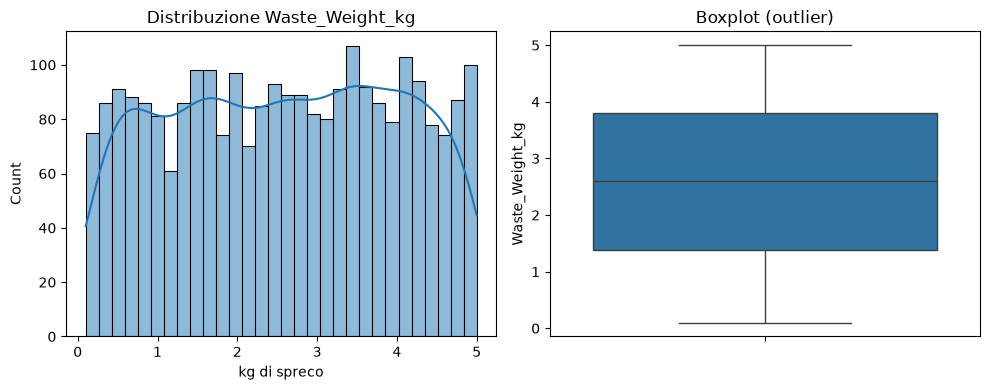

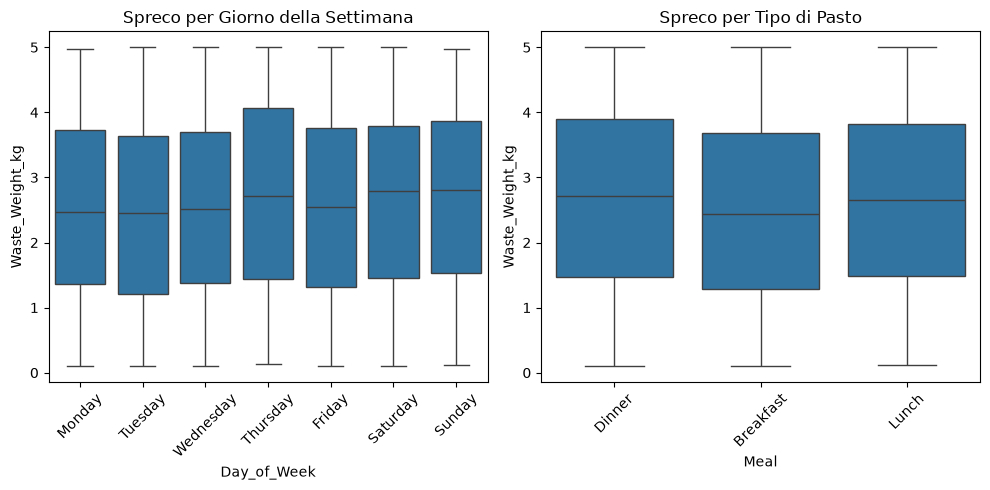

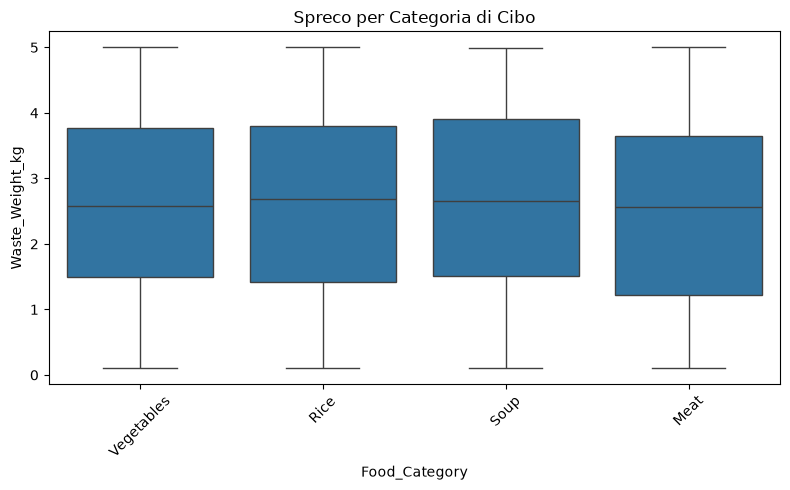

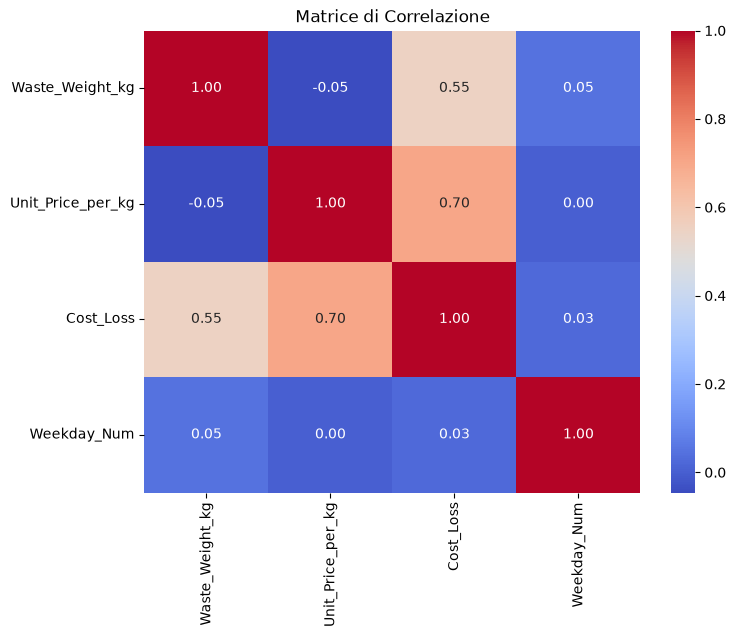


📊 Spreco medio per giorno della settimana:
Day_of_Week
Sunday       2.706250
Thursday     2.696047
Saturday     2.639629
Wednesday    2.549261
Friday       2.522658
Monday       2.519478
Tuesday      2.441794
Name: Waste_Weight_kg, dtype: float64

 Spreco medio per tipo di pasto:
Meal
Dinner       2.649965
Lunch        2.631845
Breakfast    2.476628
Name: Waste_Weight_kg, dtype: float64

 Spreco medio per categoria di cibo:
Food_Category
Soup          2.662826
Rice          2.609954
Vegetables    2.592074
Meat          2.480781
Name: Waste_Weight_kg, dtype: float64


In [5]:

# 3. VARIABILE TARGET
target_col = 'Waste_Weight_kg'
print(f"\n Variabile target: {target_col}")

# 4. DISTRIBUZIONE DELLA TARGET
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df[target_col], bins=30, kde=True)
plt.title(f'Distribuzione {target_col}')
plt.xlabel('kg di spreco')

plt.subplot(1, 2, 2)
sns.boxplot(y=df[target_col])
plt.title('Boxplot (outlier)')
plt.tight_layout()
plt.show()

# 5. ANALISI CATEGORICA
# Spreco per giorno della settimana
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.boxplot(x='Day_of_Week', y=target_col, data=df, order=order)
plt.title('Spreco per Giorno della Settimana')
plt.xticks(rotation=45)

# Spreco per tipo di pasto
plt.subplot(1, 2, 2)
sns.boxplot(x='Meal', y=target_col, data=df)
plt.title('Spreco per Tipo di Pasto')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Spreco per categoria di cibo
plt.figure(figsize=(8, 5))
sns.boxplot(x='Food_Category', y=target_col, data=df)
plt.title('Spreco per Categoria di Cibo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. CORRELAZIONI
plt.figure(figsize=(8, 6))
numeric_cols = ['Waste_Weight_kg', 'Unit_Price_per_kg', 'Cost_Loss', 'Weekday_Num']
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matrice di Correlazione')
plt.show()

# 7. STATISTICHE PER GIORNO
print("\n📊 Spreco medio per giorno della settimana:")
print(df.groupby('Day_of_Week')[target_col].mean().sort_values(ascending=False))

print("\n Spreco medio per tipo di pasto:")
print(df.groupby('Meal')[target_col].mean().sort_values(ascending=False))

print("\n Spreco medio per categoria di cibo:")
print(df.groupby('Food_Category')[target_col].mean().sort_values(ascending=False))